# 03 · Text detection

Goal: one box around each text line, in reading order, because the recognizers read one line
at a time. Detection is two-stage, using the app's own code
(`backend/app/services/layout_detection.py`):

1. **Layout** (`PP-DocLayout_plus-L`, RT-DETR) labels page regions: text, title, image, …
   Only text regions are kept; images and the outer margins are dropped.
2. **Lines** (`PP-OCRv5_server_det`, DB) runs inside each text region at full resolution.
   Its pieces are merged into lines (NMS, then row grouping).

Needs the GPU (or ~8 GB RAM on CPU).

In [1]:
# Make experimentation/src importable (this also puts backend/ on sys.path, so the
# notebooks run the app's own preprocessing, detection and recognition code).
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
%matplotlib inline

## One stage vs two stages, and the merge steps

Run on the sample page after the PORCONES preprocessing recipe.

/home/sarthak/miniconda3/envs/RenaissanceDetect/lib/python3.10/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Connectivity check to the model hoster has been skipped because `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` is enabled.


Model files already exist. Using cached files. To redownload, please delete the directory manually: `/home/sarthak/.paddlex/official_models/PP-OCRv5_server_det`.


Resized image size (3024x4032) exceeds max_side_limit of 4000. Resizing to fit within limit.


Model files already exist. Using cached files. To redownload, please delete the directory manually: `/home/sarthak/.paddlex/official_models/PP-DocLayout_plus-L`.


[2026-10-09 18:08:09,566] [    INFO] layout_detection.py:540 - layout: doc_title, text, text, image, image, paragraph_title


single-stage 84 | layout 6 | raw 38 | after NMS 36 | lines 16


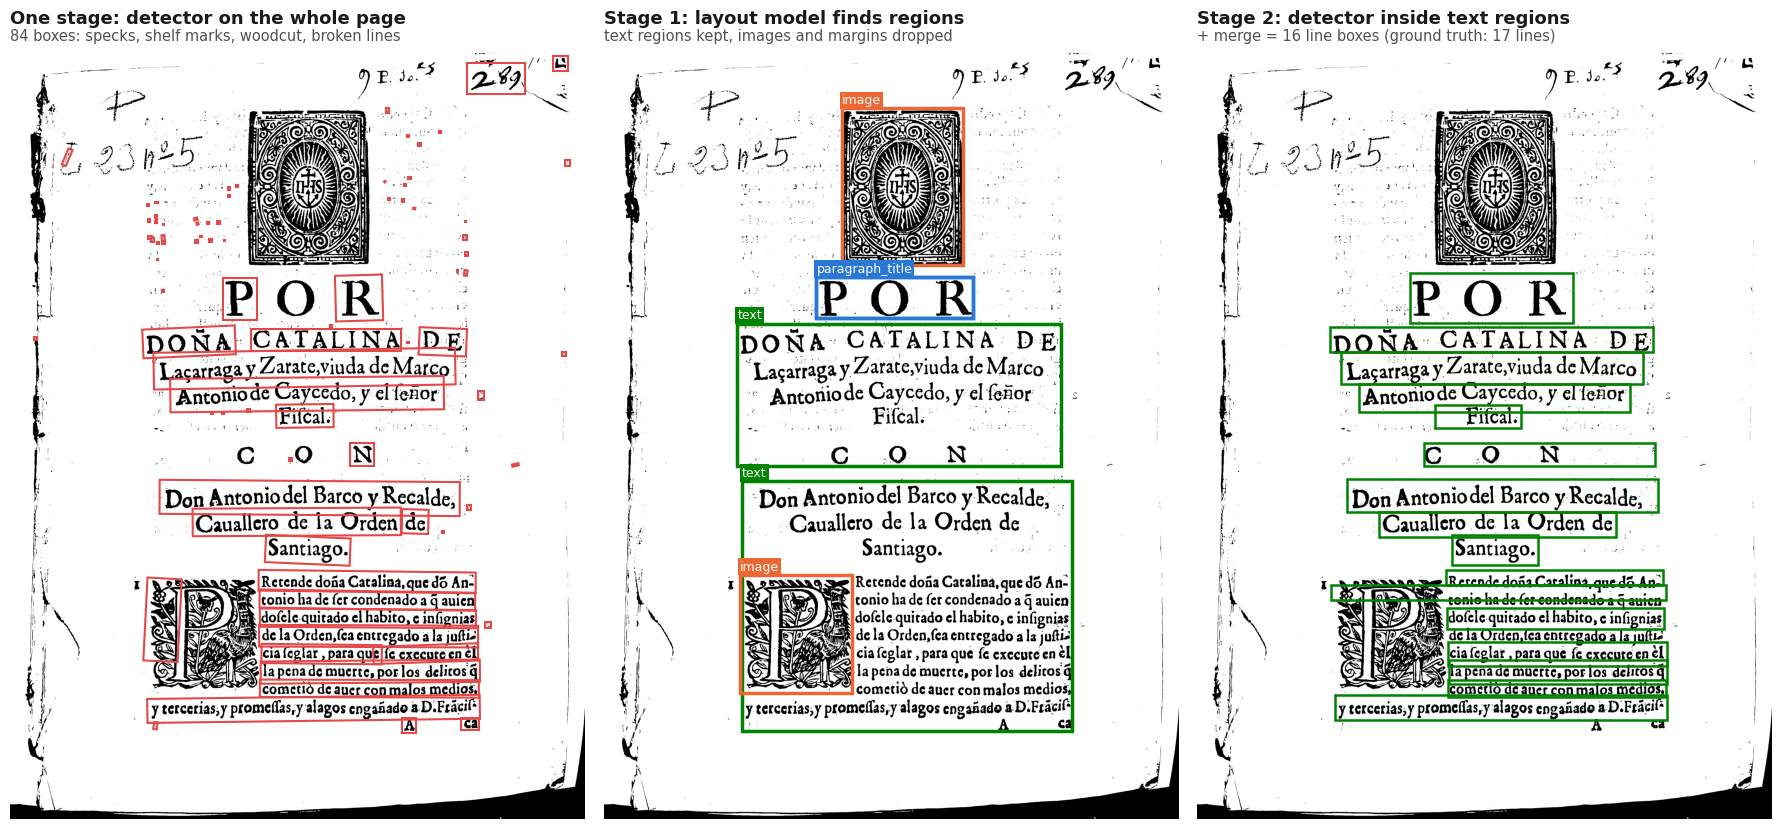

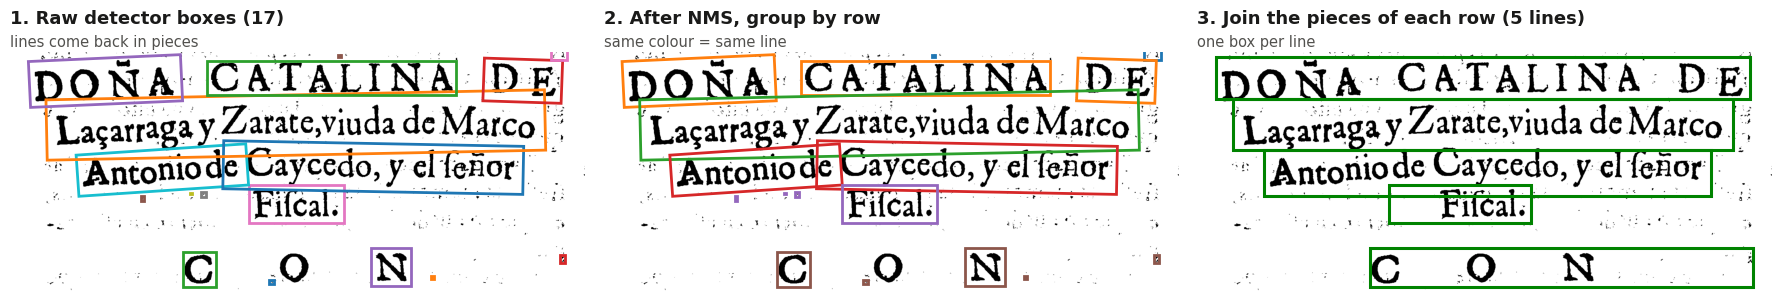

In [2]:
from src import figures
one_vs_two, merge_steps = figures.detection_steps()

**Merging.** Spaced capitals (`C O N`) and wide gaps (`DOÑA CATALINA DE`) come back as pieces.
Three rules rebuild the lines:

1. **Remove duplicates (NMS):** if two boxes overlap with IoU > 0.3, keep the more confident one.
2. **Group into rows:** boxes whose vertical centres are within half a line height share a row.
3. **Join each row:** neighbours closer than 2× a typical box width become one line box.
   Boxes tiny compared with a normal line (specks) are dropped.

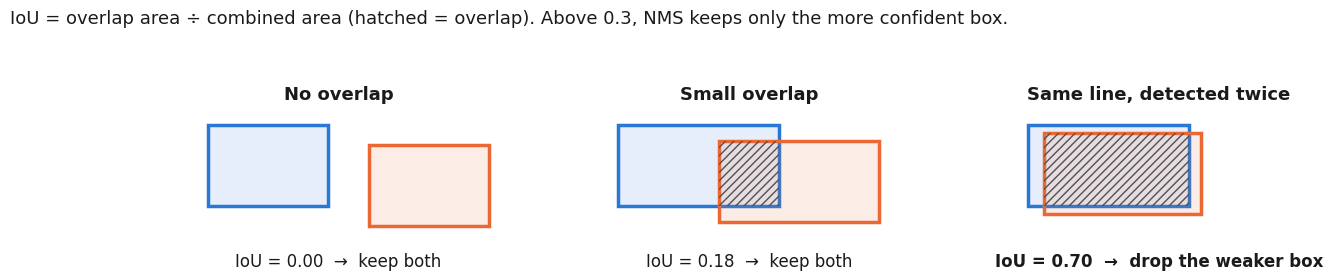

In [3]:
figures.iou_examples();

## How well does detection do on the test pages?

28 pages from 3 books no model was trained on, with and without preprocessing. Boxes were
cached by `scripts/evaluate.py detect`; the scholar's transcription gives the true number of
lines per page.

In [4]:
import json, pandas as pd
from src.pages import build_test_pages

rows = []
for page in build_test_pages():
    for pipeline in ("raw", "cleaned"):
        boxes = json.loads(page.image.with_suffix(f".{pipeline}.boxes.json").read_text())
        rows.append({"book": page.book, "pipeline": pipeline, "true lines": len(page.lines), "boxes": len(boxes)})
df = pd.DataFrame(rows).groupby(["book", "pipeline"])[["true lines", "boxes"]].sum()
df["boxes / true lines"] = (df["boxes"] / df["true lines"]).round(2)
df

true lines  boxes  boxes / true lines
book                       pipeline                                       
Buendia - Instruccion      cleaned          106    111                1.05
                           raw              106    110                1.04
PORCONES.23.5 - 1628       cleaned          155    158                1.02
                           raw              155    154                0.99
Padilla - Nobleza virtuosa cleaned          327    287                0.88
                           raw              327    331                1.01

Box counts alone do not show which lines were lost; notebook 04 measures that by matching
every true line to the recognized text.

## Memory (measured on an RTX 4060, 8 GB)

| Model | Weights | GPU memory | Time per page |
|---|---|---|---|
| Layout `PP-DocLayout_plus-L` | 125 MB | 0.55 GB (always resized to 800×800) | 0.07 s |
| Line detector `PP-OCRv5_server_det`, full 3024×4032 page | 85 MB | 6.6 GB | 3.3 s |
| Line detector, mobile version, same page | 5 MB | 1.7 GB | 0.9 s |

The detector is fully convolutional, so its working memory grows with the number of pixels.
Running it on cropped regions instead of the whole page keeps it well under 8 GB. The app
picks server models with ≥ 6 GB free VRAM, mobile with ≥ 2 GB, and the CPU otherwise.

## Experiment: fine-tuning the line detector

We fine-tuned `PP-OCRv5_server_det` on 5 hand-labelled half-pages (4 train / 1 validation)
with PaddleOCR's own trainer. The boxes are kept in `data/detection_labels/bboxes/`
(`x1 y1 x2 y2` per line); the page images were not preserved, so re-running means rendering
them again and writing PaddleOCR label lists (`train.txt` / `val.txt`) from the boxes:

```bash
git clone https://github.com/PaddlePaddle/PaddleOCR.git
wget https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv5_server_det_pretrained.pdparams
python PaddleOCR/tools/train.py -c PaddleOCR/configs/det/PP-OCRv5/PP-OCRv5_server_det.yml -o \
    Global.pretrained_model=PP-OCRv5_server_det_pretrained.pdparams Global.epoch_num=50 \
    Train.dataset.label_file_list="[train.txt]" Eval.dataset.label_file_list="[val.txt]"
```

Result: the pretrained model already scored **hmean 1.0** on the validation page, and so did
the fine-tuned one. With one validation page the experiment cannot tell them apart, so the
app ships the pretrained detector. The app's Dataset mode exports detection labels so a
larger fine-tune becomes possible.